In [1]:
!pip install wget
url = "https://raw.githubusercontent.com/kannera/keyword_course2021/main/korp_api.py"
!wget --no-check-certificate $url -O korp.py
url = "https://raw.githubusercontent.com/kannera/keyword_course2021/main/eng_corpus.py"
!wget --no-check-certificate $url -O eng_corpus.py


  Created wheel for wget: filename=wget-3.2-py3-none-any.whl size=9675 sha256=8bc5ccc37fd2a3aabe740f80fe0ad2cfa6aab8a2f4c956855be1eaa1cfbfaccb
  Stored in directory: /root/.cache/pip/wheels/a1/b6/7c/0e63e34eb06634181c63adacca38b79ff8f35c37e3c13e3c02
Successfully built wget
--2022-03-08 08:14:08--  https://raw.githubusercontent.com/kannera/keyword_course2021/main/korp_api.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 9079 (8.9K) [text/plain]
Saving to: ‘korp.py’

korp.py             100%[===================>]   8.87K  --.-KB/s    in 0s      

2022-03-08 08:14:08 (47.0 MB/s) - ‘korp.py’ saved [9079/9079]

--2022-03-08 08:14:08--  https://raw.githubusercontent.com/kannera/keyword_course2021/main/eng_corpus.py
Resolving raw.githubusercontent.com (raw.github

In [2]:
import json, os, re, sys, codecs
import matplotlib.pyplot as plt
import pandas
import wget
from korp import *
from eng_corpus import *

In [3]:
def add_date_columns_for_klk(df):
  df['date'] = df['text_issue_date'].apply(lambda x:parse_date(x) if x.count(".") == 2 else "no date")
  df['text_issue_date'] = df['text_issue_date'].apply(lambda x: "01."+x if x.count(".") == 0 else x)
  df['text_issue_date'] = df['text_issue_date'].apply(lambda x: "01."+x if x.count(".") == 1 else x)
  df['month_date'] = df['text_issue_date'].apply(lambda x:x.split(".")[-1]+"-"+x.split(".")[1]+"-01")
  df['year'] = df['text_issue_date'].apply(lambda x:x.split(".")[-1])
  
  return df

In [4]:
def get_total_frequency_for_lemma(lemma, corpus):
  if corpus in ("klk", "suomi24"):
    data = get_frequency_data_from_korp('[lemma="'+lemma+'"]', 'text_issue_date', 'klk')
    print("total frequency for", lemma, data['abs_frequency'].sum())
  if corpus in ("coha", "coca", "glowbe"):
    data = get_data_from_github(corpus)
    print("total frequency for", lemma, data[data.lemma == lemma].count()['lemma'])

In [5]:
#this counts full frequency of "medicine" in coca-corpus
#coca, coha, glowbe, suomi24, klk
get_total_frequency_for_lemma("nainen", "suomi24")

total frequency for nainen 534951


In [ ]:
get_total_frequency_for_lemma("vilja", "klk")

In [ ]:
vilja = get_frequency_data_from_korp('[lemma="wilja"]', "text_issue_date", "klk")

In [ ]:
vilja = add_date_columns_for_klk(vilja)

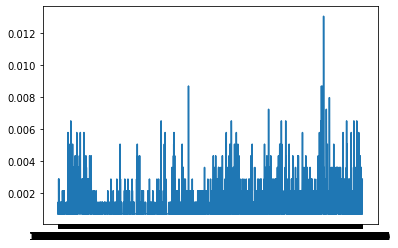

In [ ]:
#plt.figure(figsize=(8,5), dpi=200)
vilja = vilja.sort_values('date')
plt.plot(vilja[vilja.date != "no date"]['date'], vilja[vilja.date != "no date"]['rel_frequency'])

In [ ]:
print(vilja[vilja.date != "no date"].sort_values('rel_frequency', ascending=False).head(10))

     text_issue_date  rel_frequency  ...  month_date  year
482       23.10.1897       0.013062  ...  1897-10-01  1897
2513      25.10.1897       0.009433  ...  1897-10-01  1897
2308      07.10.1897       0.008708  ...  1897-10-01  1897
2467      16.03.1889       0.008708  ...  1889-03-01  1889
441       17.09.1897       0.008708  ...  1897-09-01  1897
1984      26.02.1898       0.007982  ...  1898-02-01  1898
3319      09.12.1897       0.007256  ...  1897-12-01  1897
2946      23.08.1894       0.007256  ...  1894-08-01  1894
751       05.10.1897       0.007256  ...  1897-10-01  1897
2906      28.01.1865       0.006531  ...  1865-01-01  1865

[10 rows x 6 columns]


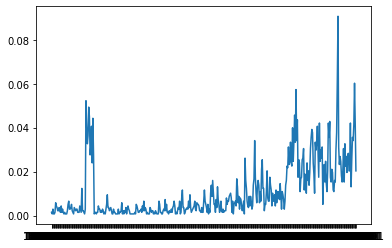

In [ ]:
month_df = vilja.groupby("month_date").sum()["rel_frequency"]
plt.plot(month_df)

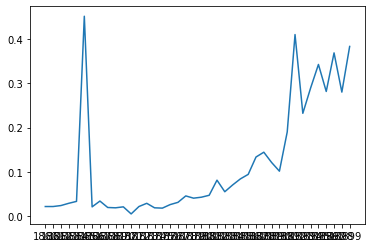

In [ ]:
year_vilja = vilja.groupby("year").sum()["rel_frequency"]
plt.plot(year_vilja)

In [ ]:
peak_vilja = get_frequency_data_from_korp('[lemma="vilja" & _.text_issue_date="10.09.1887"]', 'text_issue_title', 'klk')

In [ ]:
print(peak_vilja)

      text_issue_title  rel_frequency  abs_frequency
0         Rauman Lehti       0.002903              4
1  Oulun Ilmoituslehti       0.000726              1
2        Uusi Suometar       0.001451              2
3                 Savo       0.002177              3
4            Aamulehti       0.010885             15
5     Wiipurin Sanomat       0.000726              1
6            Satakunta       0.000726              1
7          Turun Lehti       0.002177              3
8                Tapio       0.001451              2
9         Waasan Lehti       0.001451              2


In [ ]:
non_peak_vilja = get_frequency_data_from_korp('[lemma="vilja" & _.text_issue_date="15.09.1887"]', 'text_issue_title', 'klk')

In [ ]:
print(non_peak_vilja)

  text_issue_title  rel_frequency  abs_frequency
0          Unknown       0.000726              1
1     Kansan Lehti       0.001451              2
2        Aamulehti       0.000726              1
3             Savo       0.000726              1


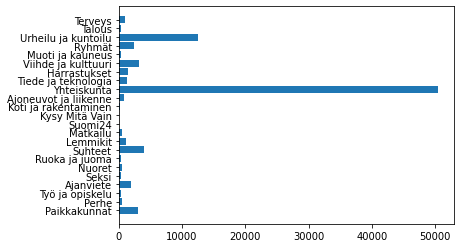

<Figure size 2000x2000 with 0 Axes>

In [ ]:
#querying for frequencies of lemma leijona ('lion') in each top level forum area (text_topic_name) in suomi24 corpus
lion = get_frequency_data_from_korp('[lemma="leijona"]', 'text_topic_name_top', 'suomi24')
plt.barh(lion['text_topic_name_top'], lion['abs_frequency'])
plt.figure(figsize=(10,10), dpi=200)
plt.rcParams.update({'font.size': 10})

plt.show()

In [ ]:
lion.to_csv('lion.csv', sep="\t")

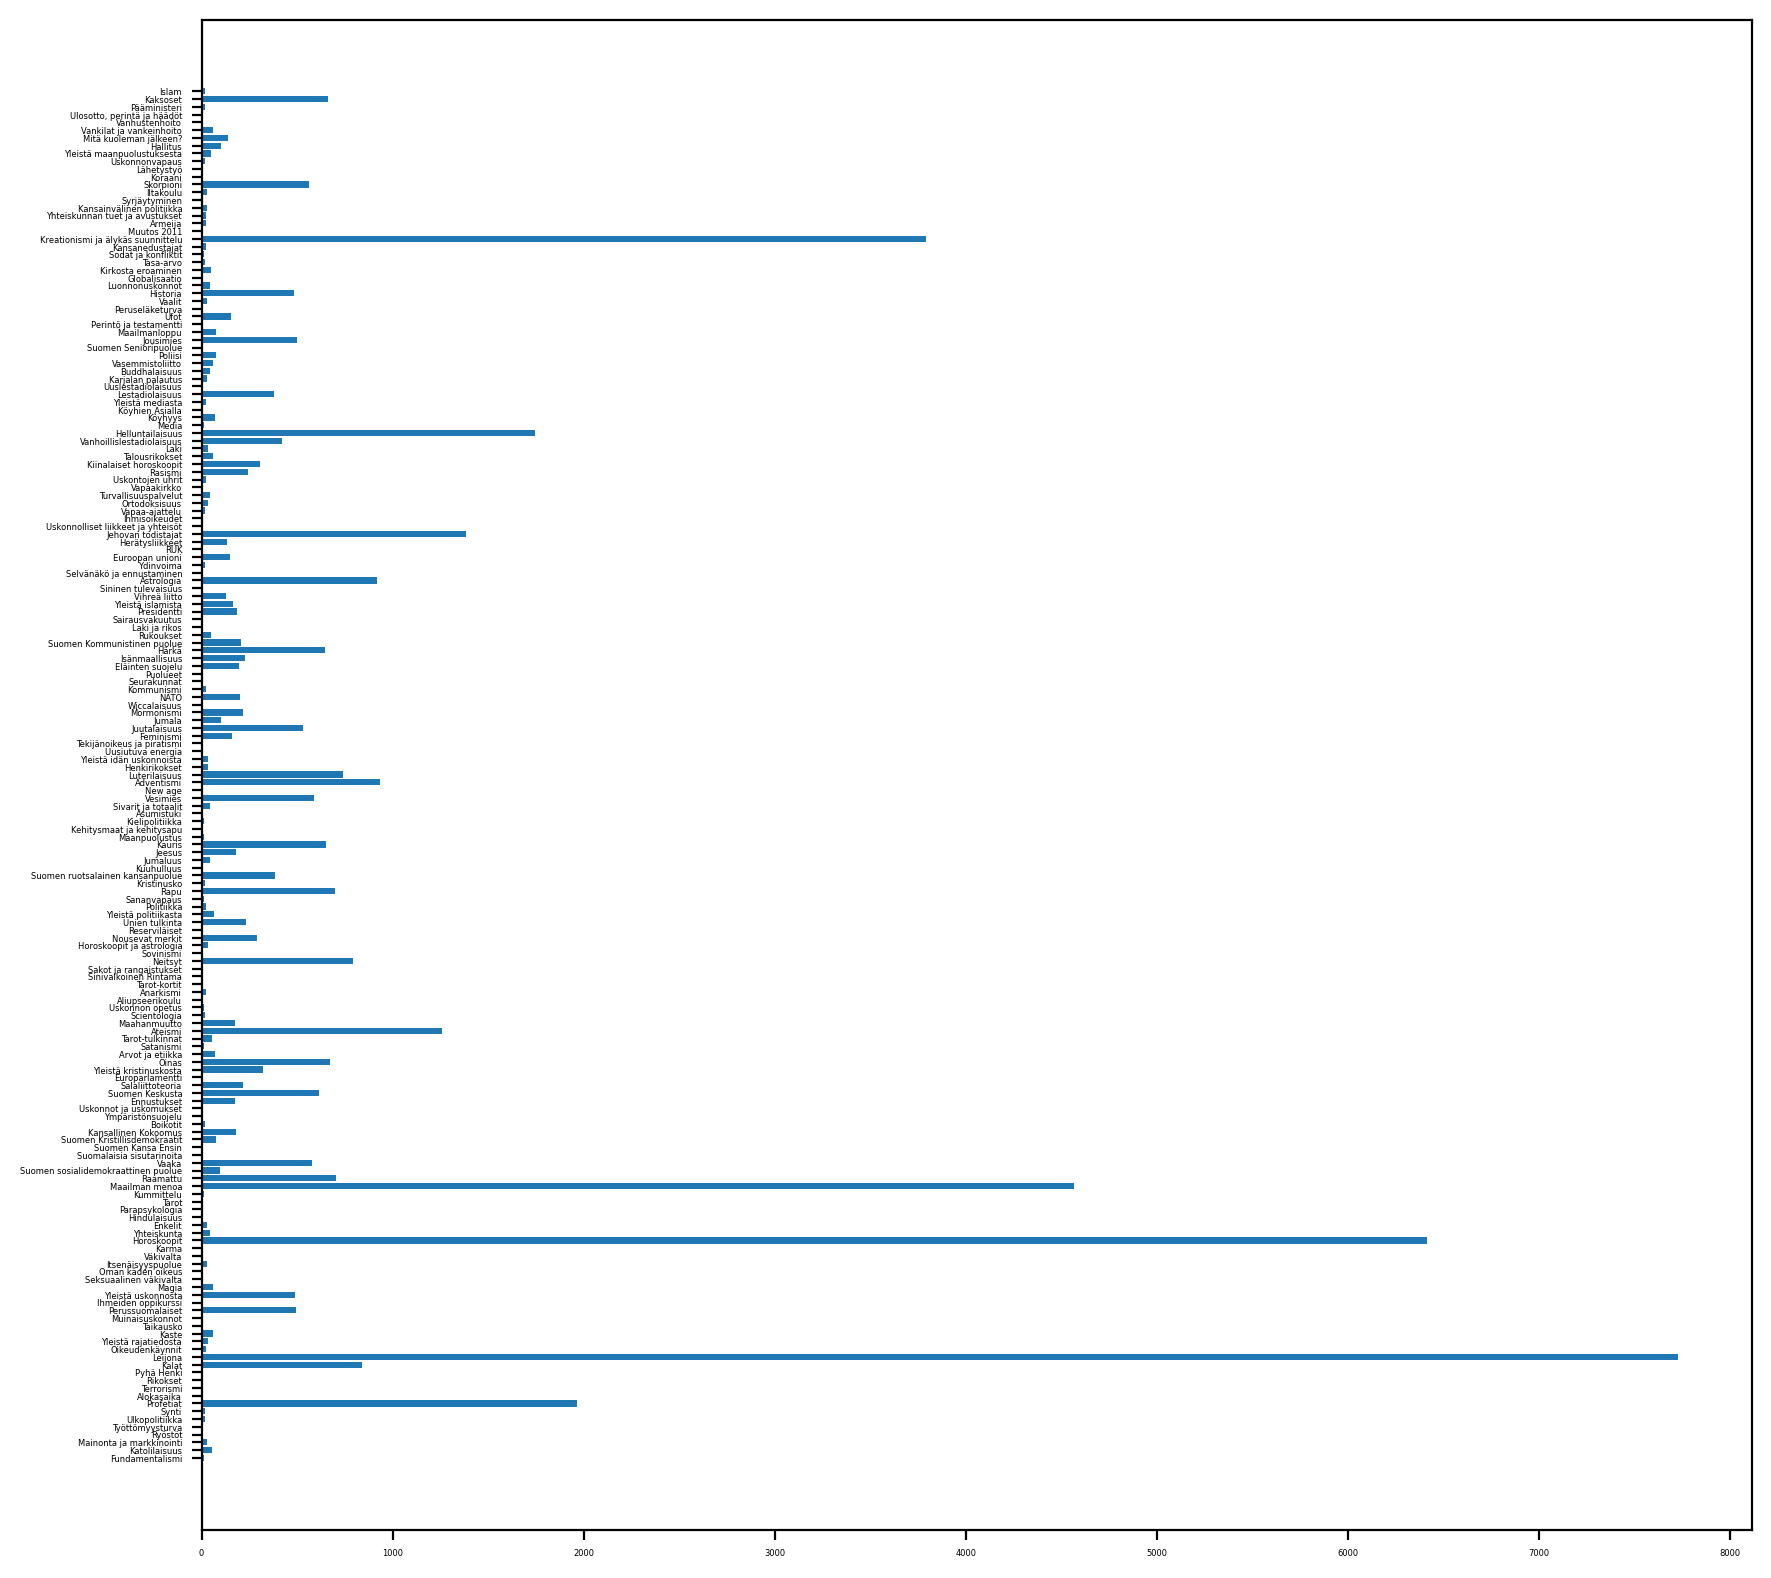

In [ ]:
#studying lower level discussion areas. The top level area is entered into the query as "_.text_topic_name_top=" and grouping is now by lower level areas (text_topic_name_leaf)
lion_soc = get_frequency_data_from_korp('[lemma="leijona" & _.text_topic_name_top = "Yhteiskunta"]', 'text_topic_name_leaf', 'suomi24')
plt.figure(figsize=(10,10), dpi=200)
plt.rcParams.update({'font.size': 3})
plt.barh(lion_soc['text_topic_name_leaf'], lion_soc['abs_frequency'])


plt.show()

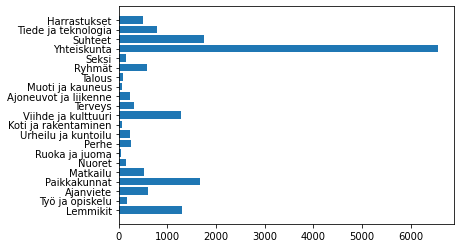

In [ ]:
#we run the same analyses for tiikeri ('tiger')
tiger = get_frequency_data_from_korp('[lemma="tiikeri"]', 'text_topic_name_top', 'suomi24')
plt.barh(tiger['text_topic_name_top'], tiger['abs_frequency'])
plt.show()

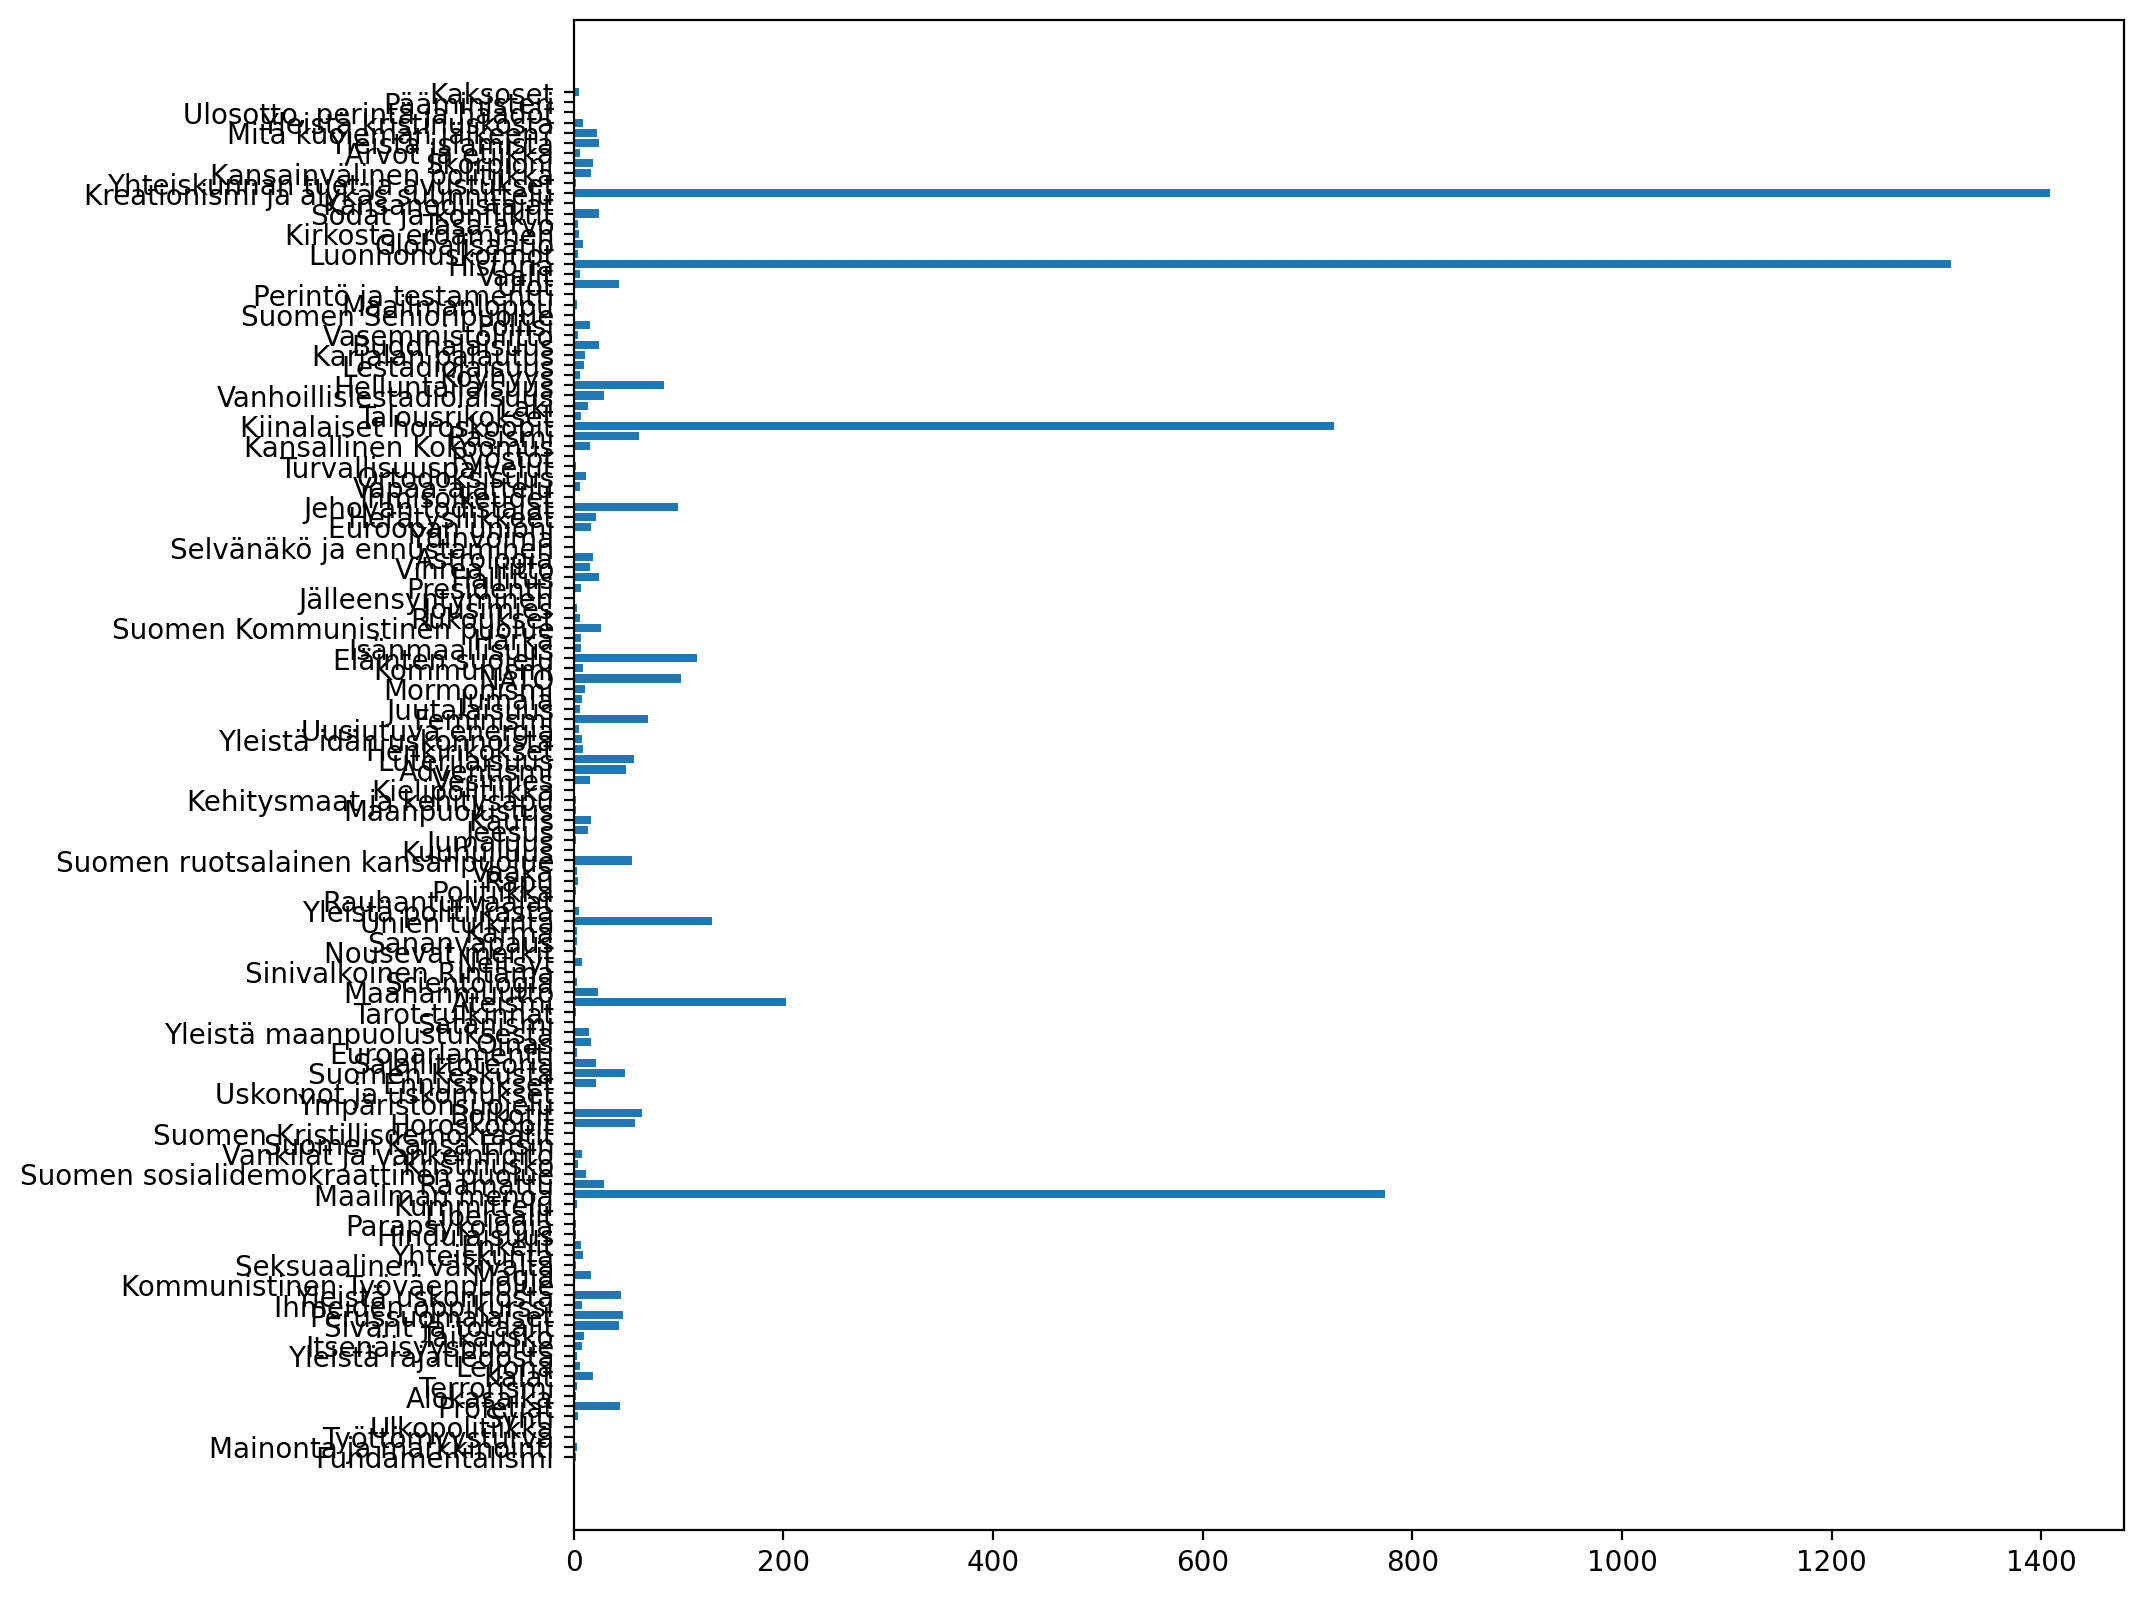

In [ ]:
tiger_soc = get_frequency_data_from_korp('[lemma="tiikeri" & _.text_topic_name_top = "Yhteiskunta"]', 'text_topic_name_leaf', 'suomi24')
plt.rcParams.update({'font.size': 10})
plt.figure(figsize=(10,10), dpi=200)
plt.barh(tiger_soc['text_topic_name_leaf'], tiger_soc['abs_frequency'])
plt.show()

In [ ]:
coha = get_data_from_github("coha")

this done
              0          1          2     3     4
0         30250       4250             2000  None
1         30250         It         it  2000  None
2         30250        was         be  2000  None
3         30250       dark       dark  2000  None
4         30250          ,          ,  2000  None
...         ...        ...        ...   ...   ...
4849127  750650          .          .  1896  None
4849128  750650         To         to  1896  None
4849129  750650        the        the  1896  None
4849130  750650  President  president  1896  None
4849131  750650          .          .   189  None

[4849132 rows x 5 columns]
        text_id       word      lemma    x1    x2
0         30250       4250             2000  None
1         30250         It         it  2000  None
2         30250        was         be  2000  None
3         30250       dark       dark  2000  None
4         30250          ,          ,  2000  None
...         ...        ...        ...   ...   ...
4849127  750

In [ ]:
print(coha.columns)

Index(['text_id', 'word', 'lemma', 'x1', 'x2', 'len', 'genre', 'year', 'title',
       'author', 'source'],
      dtype='object')


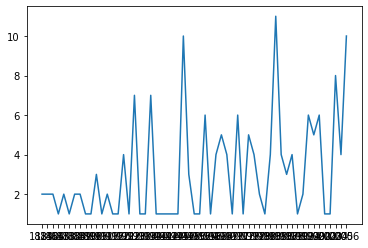

In [ ]:
plt.plot(coha[(coha.lemma=="medical")].groupby('year').count()['word'])

In [ ]:
coha_by_genre = coha[(coha.lemma=="medical")].groupby('genre').count()['word'].div(coha.groupby('genre').count()['word'])
print(coha_by_genre)

genre
FIC     0.000015
MAG     0.000064
NEWS    0.000131
NF      0.000009
Name: word, dtype: float64


In [ ]:
coca = get_data_from_github("coca")

this done
                0           1           2
0         4000241     4000241            
1         4000241           I           i
2         4000241       think       think
3         4000241          it          it
4         4000241          is          be
...           ...         ...         ...
11519970  5259141  relational  relational
11519971  5259141    database    database
11519972  5259141      engine      engine
11519973  5259141           ,           ,
11519974  5259141  developers    develope

[11519975 rows x 3 columns]
          text_id        word       lemma
0         4000241     4000241            
1         4000241           I           i
2         4000241       think       think
3         4000241          it          it
4         4000241          is          be
...           ...         ...         ...
11519970  5259141  relational  relational
11519971  5259141    database    database
11519972  5259141      engine      engine
11519973  5259141           ,        

In [ ]:
coca_by_genre = coca[(coca.lemma=="socialism")].groupby('year').count()['word'].div(coca.groupby('year').count()['word'])

In [ ]:
print(coca.columns)

Index(['text_id', 'word', 'lemma', 'year', 'sub_corpus', 'len', 'source',
       'title'],
      dtype='object')


In [ ]:
print(coca_by_genre)

year
1990    0.000009
1991    0.000021
1992         NaN
1993    0.000047
1994    0.000014
1995         NaN
1996         NaN
1997         NaN
1998         NaN
1999         NaN
2000         NaN
2001    0.000005
2002    0.000013
2003    0.000047
2004         NaN
2005         NaN
2006    0.000003
2007         NaN
2008         NaN
2009    0.000019
2010    0.000012
2011    0.000006
2012    0.000012
2013         NaN
2014    0.000020
2015    0.000004
2016         NaN
2017         NaN
2018    0.000014
2019         NaN
Name: word, dtype: float64


In [ ]:
coca_by_subcorpus = coca[(coca.lemma=="socialism")].groupby('sub_corpus').count()['word'].div(coca.groupby('sub_corpus').count()['word'])

In [ ]:
print(coca_by_subcorpus)

sub_corpus
ACAD    0.000008
BLOG    0.000018
FIC     0.000009
MAG     0.000005
MOV          NaN
NEWS    0.000005
SPOK    0.000020
TV           NaN
WEB     0.000008
Name: word, dtype: float64
